Curtis et al. (2026), Probability, parameters, and duration of immigration and extinction in microbial communities.

This exercise investigates how birth and death probabilities influence the likelihood and duration of immigration and extinction in microbial populations.

The main model parameters are:
i: Starting population abundance
N: Target population abundance for successful immigration
p: Probability of a birth event
q: Probability of a death event
q/p: Ratio indicating whether population growth or decline is favoured
c: Time constant used in the duration calculations

AI assistance: ChatGPT was used to assist with translating MATLAB code, constructing plots, explaining equations and debugging. The resulting calculations were checked against analytical expressions and published results where possible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("ready")

ready


**Immigration Probability**
This section calculates the probability that a microbial population reaches a target abundance N before becoming extinct.
For unequal birth and death probabilities, the immigration probability is:
[P_i=\frac{1-(q/p)^i}{1-(q/p)^N]

The population has absorbing boundaries at 0 (extinction) and N (successful immigration).

AI assistance: ChatGPT helped implement the probability equation in Python and generate the figures.

Verification: The reproduced curves were visually compared with the published Figure 1. The neutral case, where p = q, was tested separately.

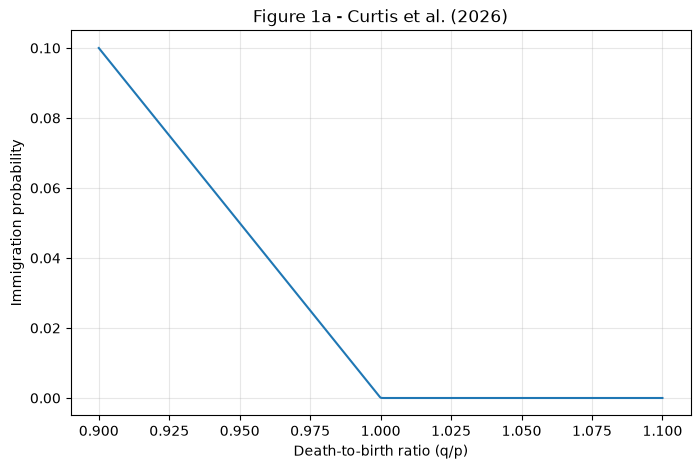

In [2]:
i = 1
N = 10000
def immigration_probability(alpha, i, N):
    if np.isclose(alpha, 1.0, rtol=0, atol=1e-12):
        return i / N
    x = np.log(alpha)
    if alpha > 1:
        return np.exp((i-N)*x) * (
            np.expm1(-i*x) / np.expm1(-N*x)
        )

    return np.expm1(i*x) / np.expm1(N*x)
ratios = np.linspace(0.9, 1.1, 500)
probabilities = [
    immigration_probability(a, i, N)
    for a in ratios
]
plt.figure(figsize=(8, 5))
plt.plot(ratios, probabilities)
plt.xlabel("Death-to-birth ratio (q/p)")
plt.ylabel("Immigration probability")
plt.title("Figure 1a - Curtis et al. (2026)")
plt.grid(alpha=0.3)
plt.show()

In [3]:
ratios = [0.90, 0.95, 0.99]
for alpha in ratios:
    result = immigration_probability(alpha, i, N)
    print("q/p =", alpha, "Probability =", round(result, 4))

q/p = 0.9 Probability = 0.1
q/p = 0.95 Probability = 0.05
q/p = 0.99 Probability = 0.01


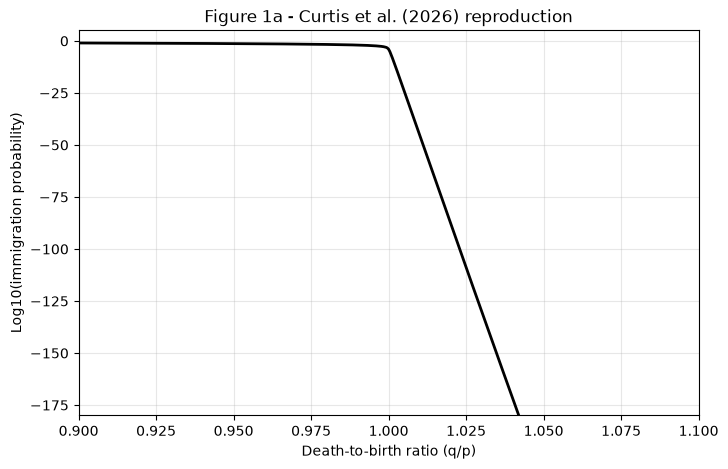

In [4]:
# Figure 1a - Immigration probability on a log10 scale
# Calculate log10 probability directly to avoid numerical underflow
def log10_immigration_probability(alpha, i, N):
    if np.isclose(alpha, 1.0, rtol=0, atol=1e-14):
        return np.log10(i / N)
    x = np.log(alpha)
    if alpha > 1:
        log_probability = (
            (i - N) * x
            + np.log(-np.expm1(-i * x))
            - np.log(-np.expm1(-N * x))
        )
    else:
        log_probability = (
            np.log(-np.expm1(i * x))
            - np.log(-np.expm1(N * x))
        )
    return log_probability / np.log(10)

# Same ratio range as your original Python graph
ratios = np.linspace(0.9, 1.1, 501)
log_probabilities = [
    log10_immigration_probability(alpha, i, N)
    for alpha in ratios
]

# Plot Figure 1a
plt.figure(figsize=(8, 5))
plt.plot(ratios, log_probabilities, color="black", linewidth=2)
plt.xlabel("Death-to-birth ratio (q/p)")
plt.ylabel("Log10(immigration probability)")
plt.title("Figure 1a - Curtis et al. (2026) reproduction")
plt.xlim(0.9, 1.1)
plt.ylim(-180, 5)
plt.grid(True, alpha=0.3)
plt.savefig("Figure_1a.png", dpi=300, bbox_inches="tight")
plt.show()


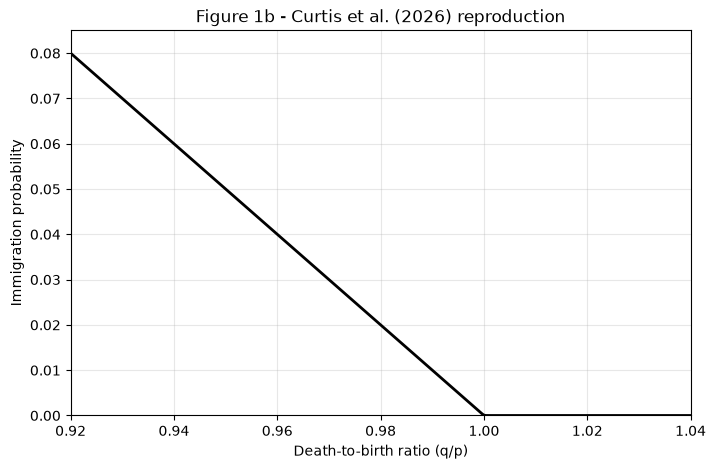

In [5]:
# Figure 1b - Non-logarithmic immigration probability
# Match the wider range in the original inset
ratios_zoom = np.linspace(0.92, 1.04, 501)

# Convert log10 probability back to ordinary probability
probabilities_zoom = [
    10 ** log10_immigration_probability(alpha, i, N)
    for alpha in ratios_zoom
]
plt.figure(figsize=(8, 5))
plt.plot(ratios_zoom, probabilities_zoom, color="black", linewidth=2)
plt.xlabel("Death-to-birth ratio (q/p)")
plt.ylabel("Immigration probability")
plt.title("Figure 1b - Curtis et al. (2026) reproduction")
plt.xlim(0.92, 1.04)
plt.ylim(0, 0.085)
plt.grid(True, alpha=0.3)
plt.savefig("Figure_1b.png", dpi=300, bbox_inches="tight")
plt.show()

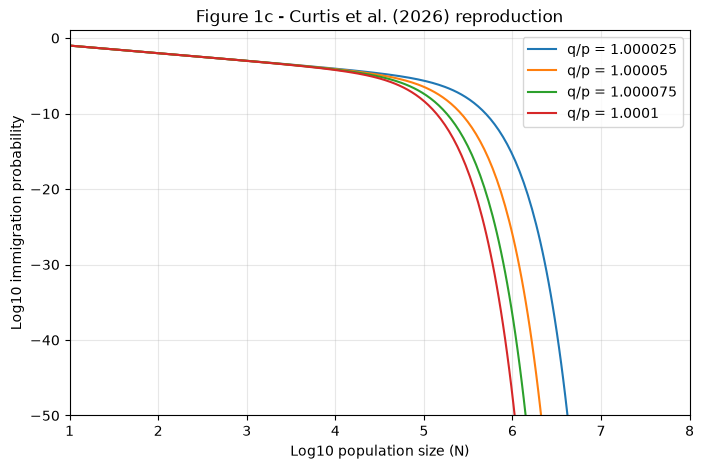

In [6]:

# Figure 1c - Immigration probability versus population size
# Population sizes from 10^1 to 10^8
log_N_values = np.linspace(1, 8, 300)
N_values = np.rint(10 ** log_N_values).astype(int)

# Different death-to-birth ratios
ratios = [1.000025, 1.00005, 1.000075, 1.0001]
plt.figure(figsize=(8, 5))
for alpha in ratios:
    log_probabilities = [
        log10_immigration_probability(alpha, i, N)
        for N in N_values
    ]
    plt.plot(
        np.log10(N_values),
        log_probabilities,
        label=f"q/p = {alpha}"
    )
plt.xlabel("Log10 population size (N)")
plt.ylabel("Log10 immigration probability")
plt.title("Figure 1c - Curtis et al. (2026) reproduction")
plt.xlim(1, 8)
plt.ylim(-50, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("Figure_1c.png", dpi=300, bbox_inches="tight")
plt.show()

**Immigration duration calculations**
This section calculates the expected duration of successful immigration using numerical recurrence and analytical methods.
The main parameters are: 
p = 0.4998
q = 0.5002
c = 1/24 days
N = 1000

The numerical immigration duration was approximately 801.5397 days, compared with an analytical value of 801.5403 days

AI assistance: ChatGPT assisted with translating the MATLAB functions into Python and plotting the results

Verification: The close agreement between numerical and analytical results supports consistency.

In [7]:
# Original parameters from the authors' MATLAB file
q = 0.5002
p = 1 - q
c = 1 / 24
r = q / p
N = 1000

# Python translation of the authors' time_to_i() function
def time_to_i(p, q, c, r, N):

    Delta = np.zeros(N)
    M = np.zeros(N)

    # Initial value
    Delta[0] = 0

    # Authors' recurrence equation
    for i in range(1, N):
        Delta[i] = r * Delta[i-1] + c / (p * i)

    # Cumulative time
    M = np.cumsum(Delta)
    return M

# Run the function
M = time_to_i(p, q, c, r, N)

print("Time to reach population 1000:", M[-1])

Time to reach population 1000: 801.5397432071151


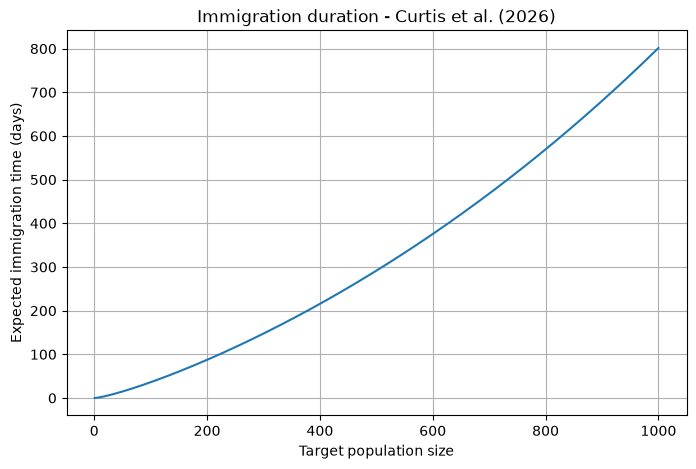

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, N + 1), M)

plt.xlabel("Target population size")
plt.ylabel("Expected immigration time (days)")
plt.title("Immigration duration - Curtis et al. (2026)")
plt.grid(True)

plt.savefig("Immigration_Duration.png", dpi=300)
plt.show()

In [9]:
# Check immigration times at different population sizes
print("Population 10:", M[9])
print("Population 100:", M[99])
print("Population 500:", M[499])
print("Population 1000:", M[999])

# Check that immigration time increases
print("Times increase:", np.all(np.diff(M) >= 0))

Population 10: 1.6124141561140424
Population 100: 36.156072529260406
Population 500: 291.5620786256923
Population 1000: 801.5397432071151
Times increase: True


In [10]:
from scipy.integrate import quad
# Translation of the authors' time_to_i_an()
def time_to_i_an(p, q, c, r, N):
    M_an = np.zeros(N)
    for k in range(2, N + 1):

        # First term: numerical integration
        term1, error = quad(
            lambda t: (1 - t**(k-1)) / (1 - t),
            0,
            1/r
        )

        # Second term: approximation used in MATLAB
        term2 = (
            np.log(k-1)
            + 0.57721
            + 1/(2*(k-1))
            - 1/(12*(k-1)**3)
        )
        M_an[k-1] = (
            c / (p*(r-1))
            * (r**k * term1 - term2)
        )
    return M_an

# Calculate the analytical results
M_an = time_to_i_an(p, q, c, r, N)
print("Recurrence result:", M[-1])
print("Analytical result:", M_an[-1])
print("Difference:", abs(M[-1] - M_an[-1]))

Recurrence result: 801.5397432071151
Analytical result: 801.540324611777
Difference: 0.0005814046619434521


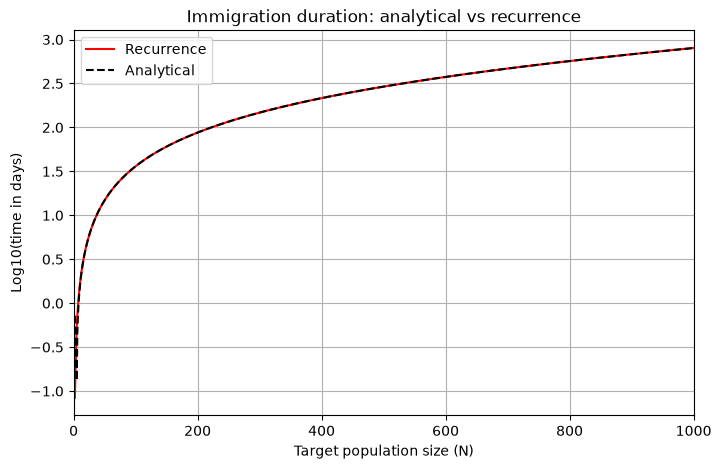

In [11]:
# Immigration duration: analytical vs recurrence
# Use population sizes matching the duration arrays
M = np.asarray(M)
M_an = np.asarray(M_an)

# Create an x-axis with the same number of values
population_sizes = np.arange(1, len(M) + 1)

# Only include positive durations
valid = (M > 0) & (M_an > 0)
plt.figure(figsize=(8, 5))
plt.plot(
    population_sizes[valid],
    np.log10(M[valid]),
    "r-",
    label="Recurrence"
)
plt.plot(
    population_sizes[valid],
    np.log10(M_an[valid]),
    "k--",
    label="Analytical"
)
plt.xlabel("Target population size (N)")
plt.ylabel("Log10(time in days)")
plt.title("Immigration duration: analytical vs recurrence")
plt.xlim(0, 1000)
plt.grid(True)
plt.legend()
plt.savefig("Immigration_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# Parameters from the authors' MATLAB code
q = 0.5002
p = 1 - q
c = 1 / 24
r = q / p
N = 1000

# Python translation of the authors' extinction() function
def extinction(p, q, c, r, N):
    Delta = np.zeros(N)
    # Initial value from the MATLAB code
    Delta[0] = -(c / p) * np.log(1 - 1/r)
    # Recurrence equation
    for i in range(1, N):
        Delta[i] = r * Delta[i-1] - c / (p*i)
    # Cumulative extinction times
    T = np.cumsum(Delta)
    return T
# Run the extinction calculation
T = extinction(p, q, c, r, N)
print("Time to extinction from population 1000:", T[-1])

Time to extinction from population 1000: 108.84558689534451


**Extinction duration calculations**
This section calculates the expected time until a microbial population reaches extinction, defined as a 'population abundance of zero'.

Using:
p = 0.4998
q = 0.5002
c = 1/24 days
N = 1000
The numerical extinction duration was approximately 108.8456 days. The analytical calculation gave approximately 108.8450 days.

AI assistance: ChatGPT helped translate the authors' MATLAB extinction functions into Python and compare the two calculation methods.

Verification: The numerical and analytical results agreed closely. However, agreement between methods does not independently confirm that every assumption and boundary condition matches the published implementation.

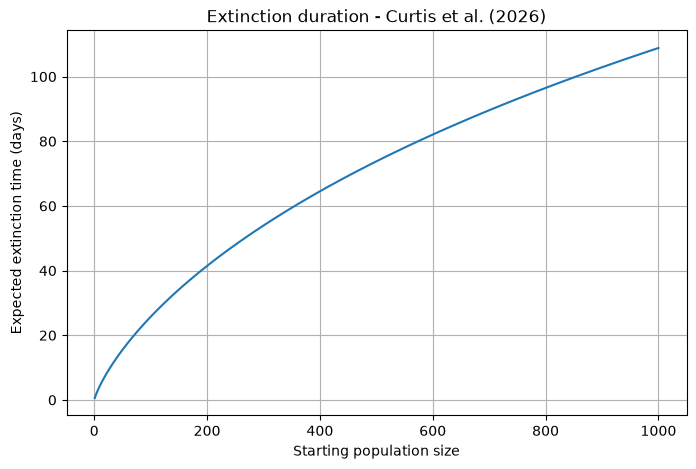

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, N + 1), T)
plt.xlabel("Starting population size")
plt.ylabel("Expected extinction time (days)")
plt.title("Extinction duration - Curtis et al. (2026)")
plt.grid(True)
plt.savefig("Extinction_Duration.png", dpi=300)
plt.show()

In [14]:
# Python translation of the authors' extinction_an()
def extinction_an(p, q, c, r, N):
    T_an = np.zeros(N)
    for k in range(2, N + 1):
        # Numerical integral from the MATLAB code
        term1, error = quad(
            lambda t: (1 - t**(k-1)) / (1 - t),
            0,
            1/r
        )
        # Authors' harmonic-number approximation
        term2 = (
            np.log(k-1)
            + 0.57721
            + 1/(2*(k-1))
            - 1/(12*(k-1)**3)
        )
        term3 = (r**k - 1) * np.log(r/(r-1))

        T_an[k-1] = (
            -c / (p*(r-1))
            * (r**k * term1 - term2 - term3)
        )
    return T_an

# Run the analytical calculation
T_an = extinction_an(p, q, c, r, N)
print("Recurrence extinction:", T[-1])
print("Analytical extinction:", T_an[-1])
print("Difference:", abs(T[-1] - T_an[-1]))

Recurrence extinction: 108.84558689534451
Analytical extinction: 108.8450054906899
Difference: 0.000581404654610651


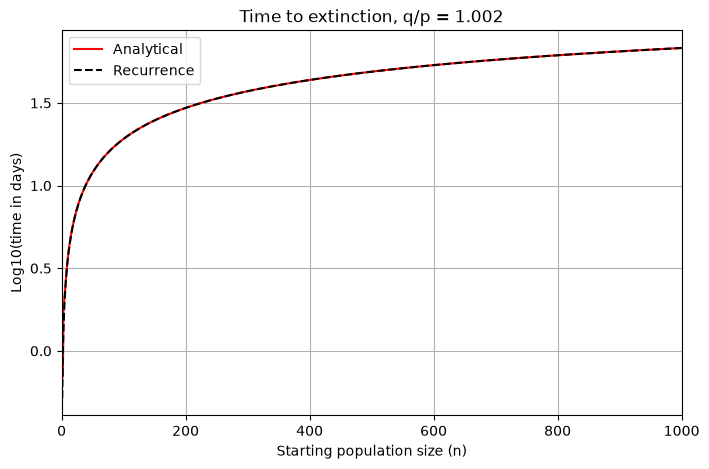

Recurrence: 67.9833663661567 days
Analytical: 67.98313357174011 days
Log10 recurrence: 1.8324026659553105


In [15]:
# Match the ratio shown in the published Figure A2
r_A2 = 1.002
p_A2 = 1 / (1 + r_A2)
q_A2 = 1 - p_A2
c_A2 = 1 / 24
N_A2 = 1000

# Calculate extinction duration
T_A2 = np.asarray(
    extinction(p_A2, q_A2, c_A2, r_A2, N_A2)
)
T_an_A2 = np.asarray(
    extinction_an(p_A2, q_A2, c_A2, r_A2, N_A2)
)
n_A2 = np.arange(1, N_A2 + 1)
plt.figure(figsize=(8, 5))
plt.plot(n_A2[T_an_A2 > 0],
         np.log10(T_an_A2[T_an_A2 > 0]),
         "r-", label="Analytical")
plt.plot(n_A2[T_A2 > 0],
         np.log10(T_A2[T_A2 > 0]),
         "k--", label="Recurrence")
plt.xlabel("Starting population size (n)")
plt.ylabel("Log10(time in days)")
plt.title("Time to extinction, q/p = 1.002")
plt.xlim(0, 1000)
plt.grid(True)
plt.legend()
plt.savefig("Figure_A2_reproduction.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Recurrence:", T_A2[-1], "days")
print("Analytical:", T_an_A2[-1], "days")
print("Log10 recurrence:", np.log10(T_A2[-1]))

Duration at N=1000: 1584.7756288586456 days
Log10 duration: 3.199967783874767


C:\Users\nikij\AppData\Local\Temp\ipykernel_19772\2931643123.py:15: RuntimeWarning: divide by zero encountered in log10
  np.log10(M_test),


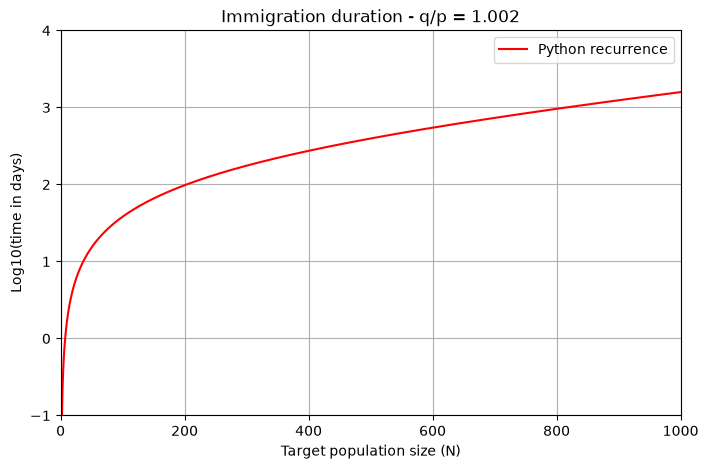

In [16]:
# Test the ratio used in the published Figure A1a
r_test = 1.002
p_test = 1 / (1 + r_test)
q_test = r_test / (1 + r_test)
c_test = 1 / 24
N_test = 1000
M_test = time_to_i(
    p_test, q_test, c_test, r_test, N_test
)
print("Duration at N=1000:", M_test[-1], "days")
print("Log10 duration:", np.log10(M_test[-1]))
plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, N_test + 1),
    np.log10(M_test),
    color="red",
    label="Python recurrence"
)
plt.xlabel("Target population size (N)")
plt.ylabel("Log10(time in days)")
plt.title("Immigration duration - q/p = 1.002")
plt.xlim(0, 1000)
plt.ylim(-1, 4)
plt.grid(True)
plt.legend()
plt.show()

In [17]:
import pandas as pd
results = pd.DataFrame({
    "Calculation": ["Immigration", "Extinction"],
    "Recurrence_days": [M[-1], T[-1]],
    "Analytical_days": [M_an[-1], T_an[-1]]
})
results["Absolute_difference"] = abs(
    results["Recurrence_days"] -
    results["Analytical_days"]
)
print(results)
results.to_csv("Day1_Results.csv", index=False)

   Calculation  Recurrence_days  Analytical_days  Absolute_difference
0  Immigration       801.539743       801.540325             0.000581
1   Extinction       108.845587       108.845005             0.000581


In [18]:
# Investigate the effect of the time-scale parameter
c_original = 1 / 24
c_test = 0.1
duration_original = M_test[-1]

# Valid if duration scales linearly with c
duration_test = duration_original * (c_test / c_original)
print("Duration with c = 1/24:", duration_original, "days")
print("Duration with c = 0.1:", duration_test, "days")
print("Log10 duration with c = 0.1:", np.log10(duration_test))

Duration with c = 1/24: 1584.7756288586456 days
Duration with c = 0.1: 3803.46150926075 days
Log10 duration with c = 0.1: 3.580179025586373


**Comparison with published Table 1**
This section compares the immigration and extinction durations calculated in Python with the values reported in the paper.

The aim is to determine whether the translated Python reproduces the published numerical results.

Some calculated values differed from Table 1. The differences were investigated by checking the death-to-birth ratio and testing the sensitivity of the results to the time constant.

AI assistance: ChatGPT assisted with organising the numerical comparisons and investigating possible causes of disagreement.

Verification: Differences from the published values are recorded explicitly rather than assuming the reproduction is exact.

In [19]:
# Compare our calculations with Table 1
import pandas as pd
N = 1000
c = 1 / 24  #authors' MATLAB example
ratios = [1.01, 1.001, 1.0001]
published_immigration = [1960000, 2130, 1300]
published_extinction = [59, 234, 1010]
rows = []
for j, r in enumerate(ratios):
    # Calculate p and q so that p + q = 1
    p = 1 / (1 + r)
    q = r / (1 + r)

    # Reuse the authors' translated functions
    M_result = time_to_i(p, q, c, r, N)[-1]
    T_result = extinction(p, q, c, r, N)[-1]
    rows.append({
        "q/p": r,
        "Python immigration": M_result,
        "Table 1 immigration": published_immigration[j],
        "Python extinction": T_result,
        "Table 1 extinction": published_extinction[j]
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
comparison.to_csv("Table1_Comparison.csv", index=False)

   q/p  Python immigration  Table 1 immigration  Python extinction  Table 1 extinction
1.0100       810042.162541              1960000          24.805373                  59
1.0010          891.198797                 2130          97.779313                 234
1.0001          566.200410                 1300         241.022930                1010


In [20]:
# Step 18: Compare published results with Python
comparison["Immigration ratio"] = (
    comparison["Table 1 immigration"] /
    comparison["Python immigration"]
)
comparison["Extinction ratio"] = (
    comparison["Table 1 extinction"] /
    comparison["Python extinction"]
)
print(comparison[
    ["q/p", "Immigration ratio", "Extinction ratio"]
].round(3).to_string(index=False))

  q/p  Immigration ratio  Extinction ratio
1.010              2.420             2.379
1.001              2.390             2.393
1.000              2.296             4.190


**Sensitivity analysis: Time constant**
This section investigates whether changing the time constant affects agreement with the published Table 1 values.

A time constant of c = 0.1 was tested as an alternative to c = 1/24 days.

This change improved agreement with several published immigration and extinction durations. However, the extinction result for q/p = 1.0001 remained inconsistent with the published value.

limitation: The value c = 0.1 was used as a sensitivity test and has not been verified as the time constant used by the authors.

AI assistance: ChatGPT helped investigate this discrepancy and compare the numerical results.

In [21]:
# Diagnostic: test a different time constant
c_test = 0.1
N = 1000
for r in [1.01, 1.001, 1.0001]:
    p = 1 / (1 + r)
    q = r / (1 + r)
    M_test = time_to_i(p, q, c_test, r, N)[-1]
    T_test = extinction(p, q, c_test, r, N)[-1]
    print("q/p =", r)
    print("Immigration:", round(M_test, 2), "days")
    print("Extinction:", round(T_test, 2), "days")
    print()

q/p = 1.01
Immigration: 1944101.19 days
Extinction: 59.53 days

q/p = 1.001
Immigration: 2138.88 days
Extinction: 234.67 days

q/p = 1.0001
Immigration: 1358.88 days
Extinction: 578.46 days



In [22]:
# Check the remaining Table 1 discrepancy
r = 1.0001
p = 1 / (1 + r)
q = r / (1 + r)
c = 0.1
N = 1000
# Recurrence calculation
T_check = extinction(p, q, c, r, N)

# Analytical calculation
T_an_check = extinction_an(p, q, c, r, N)
print("Recurrence extinction:", T_check[-1])
print("Analytical extinction:", T_an_check[-1])
print("Published Table 1:", 1010)
print("Difference between Python methods:",
      abs(T_check[-1] - T_an_check[-1]))

Recurrence extinction: 578.4550317540447
Analytical extinction: 578.4438682262639
Published Table 1: 1010
Difference between Python methods: 0.01116352778080909


In [23]:
#Extinction recurrence
r = 1.0001
p = 1 / (1 + r)
q = r / (1 + r)
c = 0.1
N = 1000
T_check = extinction(p, q, c, r, N)
print("Birth probability p:", p)
print("Death probability q:", q)
print("Death-to-birth ratio:", q / p)
print("Extinction from 1 bacterium:", T_check[0])
print("Extinction from 10 bacteria:", T_check[9])
print("Extinction from 100 bacteria:", T_check[99])
print("Extinction from 1000 bacteria:", T_check[999])

Birth probability p: 0.49997500124993755
Death probability q: 0.5000249987500626
Death-to-birth ratio: 1.0001
Extinction from 1 bacterium: 1.8421801777989397
Extinction from 10 bacteria: 14.57067799629751
Extinction from 100 bacteria: 101.01498946271451
Extinction from 1000 bacteria: 578.4550317540447


**Supplementary Figure A3: Effect of random noise**
This section investigates how random variation in birth probability affects predicted extinction duration.

The baseline parameters were:
p = 0.4998
q = 0.5002
c = 1/24 days
N = 1000.

Uniform noise of approximately ±0.0002 was applied to the birth probability. Ten simulations were performed using random seeds 0–9.

The baseline extinction duration was approximately 108.85 days. The noisy simulations produced a mean of 114.95 days, a standard deviation of 39.93 days, and a range from 78.76 to 218.57 days.

AI assistance: ChatGPT helped translate the MATLAB noise function, implement reproducible random simulations and create the comparison plot.

Verification: The reproduced figure was qualitatively similar to the published Figure A3. Exact random trajectories were however not independently verified.

In [24]:
# Parameters from the authors' MATLAB example
q = 0.5002
p = 1 - q
c = 1 / 24
r = q / p
N = 1000

# Python translation of extinction_noise()
def extinction_noise(p, q, c, r, N, noise, seed=42):
    rng = np.random.default_rng(seed)
    Delta = np.zeros(N)
    T = np.zeros(N)
    
    # Authors' noise procedure
    np_new = p + (0.5 - rng.random()) * noise
    r_new = (1 - np_new) / np_new

    # Initial condition from MATLAB
    Delta[0] = -(c / p) * np.log(1 - 1/r_new)

    # Recurrence equation
    for i in range(1, N):
        Delta[i] = (
            r_new * Delta[i-1]
            - c / (np_new * i)
        )
    T = np.cumsum(Delta)
    return T

# Run one noisy calculation
T_noise = extinction_noise(
    p, q, c, r, N,
    noise=0.0004,
    seed=42
)
print("Noisy extinction time:", T_noise[-1])

Noisy extinction time: 87.5637566510841


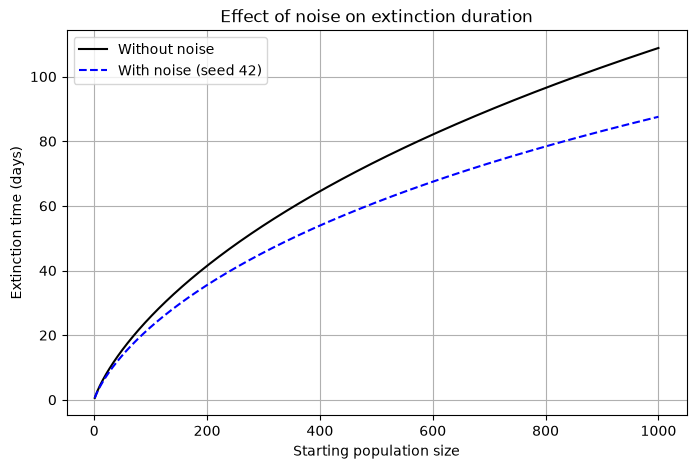

In [25]:
# Original extinction calculation without noise
T_original = extinction(p, q, c, r, N)

# Compare original and noisy calculations
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, N + 1),
    T_original,
    label="Without noise",
    color="black"
)
plt.plot(
    range(1, N + 1),
    T_noise,
    label="With noise (seed 42)",
    color="blue",
    linestyle="--"
)
plt.xlabel("Starting population size")
plt.ylabel("Extinction time (days)")
plt.title("Effect of noise on extinction duration")
plt.legend()
plt.grid(True)
plt.savefig("Figure_A3_initial.png", dpi=300)
plt.show()

In [26]:
# Store extinction times from 10 noisy simulations
extinction_times = []
for seed in range(10):
    T_sim = extinction_noise(
        p, q, c, r, N,
        noise=0.0004,
        seed=seed
    )
    extinction_times.append(T_sim[-1])

# Convert to NumPy array
extinction_times = np.array(extinction_times)

print("Without noise:", round(T_original[-1], 2), "days")
print("Minimum with noise:", round(np.min(extinction_times), 2), "days")
print("Maximum with noise:", round(np.max(extinction_times), 2), "days")
print("Mean with noise:", round(np.mean(extinction_times), 2), "days")
print("Standard deviation:", round(np.std(extinction_times), 2), "days")

Without noise: 108.85 days
Minimum with noise: 78.76 days
Maximum with noise: 218.57 days
Mean with noise: 114.95 days
Standard deviation: 39.93 days


In [27]:
noise_results = pd.DataFrame({
    "Seed": range(10),
    "Extinction_time_days": extinction_times
})
noise_results.to_csv(
    "Figure_A3_noise_results.csv",
    index=False
)
print(noise_results)
print("CSV file saved successfully.")

   Seed  Extinction_time_days
0     0             96.736626
1     1            107.642350
2     2            145.041678
3     3            218.573857
4     4             78.758036
5     5             85.772147
6     6            105.083003
7     7             97.648879
8     8            131.975466
9     9             82.280091
CSV file saved successfully.


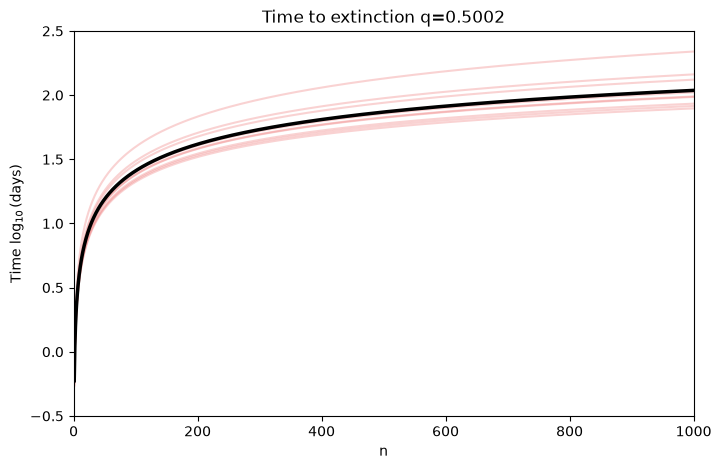

In [28]:
plt.figure(figsize=(8, 5))

# Plot 10 noisy extinction curves
for seed in range(10):
    T_sim = extinction_noise(
        p, q, c, r, N,
        noise=0.0004,
        seed=seed
    )
    plt.plot(
        range(1, N + 1),
        np.log10(T_sim),
        color="lightcoral",
        alpha=0.35,
        linewidth=1.5
    )

# Plot original extinction curve
plt.plot(
    range(1, N + 1),
    np.log10(T_original),
    color="black",
    linewidth=2.5
)
plt.xlabel("n")
plt.ylabel(r"Time $\log_{10}$(days)")
plt.title("Time to extinction q=0.5002")
plt.xlim(0, 1000)
plt.ylim(-0.5, 2.5)
plt.savefig(
    "Figure_A3_reproduction.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Neutral extinction: Carrying-capacity test**
This section examines neutral extinction calculations using equal birth and death probabilities.

A carrying capacity of K = 1000 and time constant c = 1/24 days were used.

The analytical calculation gave extinction times of approximately 0.6237, 1.1641, 4.6296 and 27.4758 days for starting populations of 1, 2, 10 and 100.

AI assistance: ChatGPT helped implement the expression in Python.

Limitation: The carrying-capacity boundary condition and its correspondence with the authors' published model have not been independently verified. These results are therefore treated as a mathematical test rather than a confirmed reproduction of the published neutral extinction results.

In [29]:

# Exercise 4: Equal birth and death probabilities

p = 0.5
q = 0.5
N = 1000

# Neutral immigration probability
def neutral_probability(i, N):
    return i / N

for i in [1, 2, 10]:
    P = neutral_probability(i, N)

    print("Starting population:", i)
    print("Target population:", N)
    print("Probability:", P)
    print()

Starting population: 1
Target population: 1000
Probability: 0.001

Starting population: 2
Target population: 1000
Probability: 0.002

Starting population: 10
Target population: 1000
Probability: 0.01



In [30]:
from scipy.special import digamma
# Harmonic number H_n
def harmonic(n):
    return digamma(n + 1) + np.euler_gamma

# Neutral extinction with carrying capacity
def neutral_extinction(i, K, c):
    return 2 * c * (
        i * (harmonic(K - 1) - harmonic(i - 1))
        + (i - 1)
    )
    
# Test parameters
K = 1000
c = 1 / 24
for i in [1, 2, 10, 100]:
    T = neutral_extinction(i, K, c)
    print("Starting population:", i)
    print("Extinction time:", round(T, 4), "days")
    print()

Starting population: 1
Extinction time: 0.6237 days

Starting population: 2
Extinction time: 1.1641 days

Starting population: 10
Extinction time: 4.6296 days

Starting population: 100
Extinction time: 27.4758 days



**Numerical consistency check**
This section compares the neutral extinction analytical expression with a recurrence derived from the same mathematical relationship.

For starting populations of 1, 2, 10 and 100, the recurrence and analytical calculations agreed to the displayed precision.

An earlier AI-suggested recurrence produced incorrect results because of an inappropriate upper-boundary term. This error was identified through comparison with the analytical expression and corrected.

Verification: The revised calculations demonstrate internal numerical consistency. However, because the two approaches are mathematically related, their agreement does not independently validate the authors' biological boundary conditions.

In [31]:
# Parameters
K = 1000
c = 1 / 24

# Correct recurrence for the neutral extinction formula
Delta = np.zeros(K)

# Upper boundary condition
Delta[K - 1] = 0

# Calculate backwards
for i in range(K - 2, -1, -1):
    n = i + 1
    Delta[i] = Delta[i + 1] + 2 * c / n

# Calculate extinction time
T_recurrence = np.cumsum(Delta)

# Compare results
for i in [1, 2, 10, 100]:
    analytical = neutral_extinction(i, K, c)
    recurrence = T_recurrence[i - 1]

    print("Starting population:", i)
    print("Analytical:", round(analytical, 4))
    print("Recurrence:", round(recurrence, 4))
    print("Difference:", round(abs(analytical - recurrence), 8))
    print()

Starting population: 1
Analytical: 0.6237
Recurrence: 0.6237
Difference: 0.0

Starting population: 2
Analytical: 1.1641
Recurrence: 1.1641
Difference: 0.0

Starting population: 10
Analytical: 4.6296
Recurrence: 4.6296
Difference: 0.0

Starting population: 100
Analytical: 27.4758
Recurrence: 27.4758
Difference: 0.0



**Software versions and reproducibility**
The calculations were performed in Python using Jupyter Notebook.
Software versions:
Python 3.14.8
NumPy 2.5.4
SciPy 1.18.1
Matplotlib 3.11.2
Pandas 3.0.6

The notebook contains the numerical calculations, reproduced figures, parameter values and recorded random seeds.

AI assistance: ChatGPT assisted with translating MATLAB code, plotting, debugging and numerical checks. AI-generated or AI-assisted code is identified in the relevant sections of the notebook.

Remaining limitations: Some published Table 1 values remain unmatched, and the neutral extinction carrying-capacity boundary condition requires further verification.

In [32]:
import sys
import numpy
import scipy
import matplotlib
import pandas

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pandas:", pandas.__version__)

Python: 3.14.8
NumPy: 2.5.4
SciPy: 1.18.1
Matplotlib: 3.11.2
Pandas: 3.0.6
